<a href="https://colab.research.google.com/github/Andoniadou-Lab/PCP_sc_spatial/blob/main/London_team/xenium_integration_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import packages

In [ ]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from scipy.stats import spearmanr

/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/scanpy/_utils/__init__.py:35: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/scanpy/readwrite.py:15: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


# Load dataset

In [ ]:
spatial_data = sc.read_h5ad("/mnt/g/PCP_xenium/merged_adata_0613.h5ad")
sc.pp.filter_genes(spatial_data, min_cells=200)

/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


### Removing genes that are amongst the top expressin transcripts. These will just provide noise for the integration

In [ ]:
import pandas as pd
top_contaminating_genes = pd.read_csv("/mnt/g/PCP_xenium/top_contaminating_genes.csv")
genes_to_keep = [gene for gene in spatial_data.var_names if gene not in top_contaminating_genes["feature_name"].values]


In [ ]:
len(spatial_data.var_names)

4448

In [ ]:
len(genes_to_keep)

4418

In [ ]:
spatial_data = spatial_data[:,genes_to_keep].copy()
spatial_data

/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 321822 × 4418
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'counts_left_after_noisy_genes', 'ID'
    var: 'n_cells'
    obsm: 'spatial'

### Training scVI model

In [ ]:
import scvi
scvi.model.SCVI.setup_anndata(spatial_data, batch_key="ID")
vae = scvi.model.SCVI(spatial_data , n_layers=2, n_latent=20, gene_likelihood="nb")


In [ ]:
vae.train(max_epochs=200,early_stopping_patience=20,early_stopping=True)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA RTX 5000 Ada Generation') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=55` in the `DataLoader` to improve performance.
/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'val_

Epoch 200/200: 100%|██████████| 200/200 [1:32:52<00:00, 27.45s/it, v_num=1, train_loss_step=1.85e+3, train_loss_epoch=1.88e+3]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [1:32:52<00:00, 27.86s/it, v_num=1, train_loss_step=1.85e+3, train_loss_epoch=1.88e+3]


In [ ]:
import scvi
vae_dir = "/mnt/g/PCP_xenium/vae_0616/"
#vae.save(dir_path=vae_dir)
vae = scvi.model.SCVI.load(vae_dir, spatial_data)

INFO     File /mnt/g/PCP_xenium/vae_0616/model.pt already downloaded                                               


/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/scvi/data/fields/_base_field.py:63: UserWarning: adata.X does not contain unnormalized count data. Are you sure this is what you want?
  self.validate_field(adata)


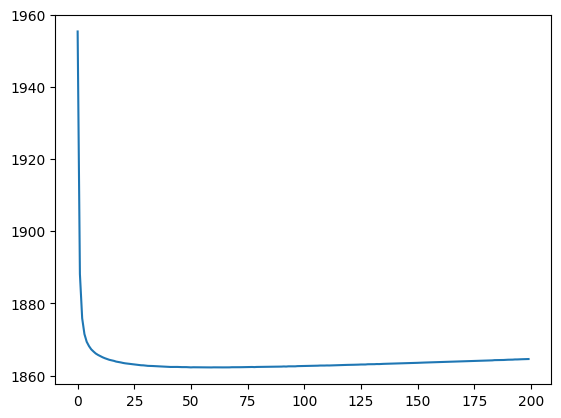

In [ ]:
#plot convergence
import matplotlib.pyplot as plt
plt.plot(vae.history["reconstruction_loss_train"], label="train")

### Getting latent representation and calculating UMAP

In [ ]:
spatial_data.obsm["X_scVI"] = vae.get_latent_representation()


In [ ]:
sc.pp.neighbors(spatial_data, use_rep="X_scVI",n_neighbors=40)
sc.tl.leiden(spatial_data, resolution=1.5, key_added="leiden_scVI", random_state=42,flavor="igraph")
sc.tl.umap(spatial_data,min_dist=0.1)

/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:423: FutureWarning: The method obsm_keys is deprecated and will be removed in the future. Use obsm instead of obsm_keys. (e.g. `k in adata.obsm` or `adata.obsm.keys() | {'u'}`)
  if "X_diffmap" in adata.obsm_keys():


In [ ]:
sc.pp.log1p(spatial_data)

### Plotting genes that help separate stem-like vs epithelial cells

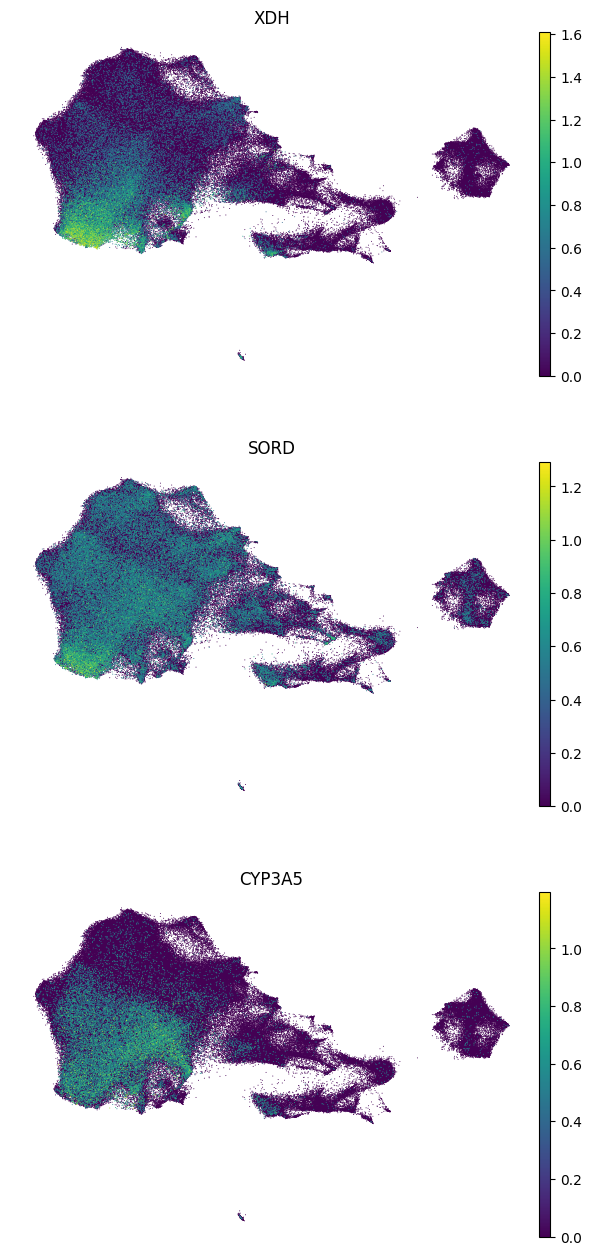

In [ ]:
genes= ['EPS8L1',
 'LINC02474',
 'TSPAN6',
 'PDZK1IP1',
 'ELF3-AS1',
 'ENSG00000203472.3',
 'XDH',
 'ENSG00000268628.2',
 'CLDN23',
 'B3GALT5',
 'SORD',
 'VSIG2',
 'ALDH1A3-AS1',
 'TJP3',
 'ATP10B',
 'SERPINB11',
 'ENSG00000289396.1',
 'CYP3A5',
 'PCDH1',
 'SLC35F4']

genes = [g for g in genes if g in spatial_data.var_names]

sc.pl.umap(
    spatial_data,
    color=genes,
    frameon=False,
    sort_order=True,
    ncols=1,size=2
)

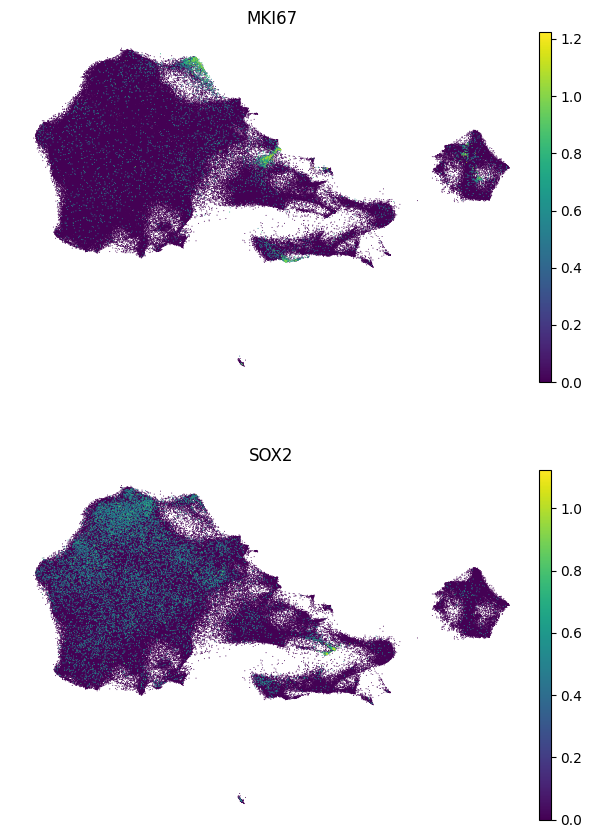

In [ ]:
sc.pl.umap(
    spatial_data,
    color=["MKI67","SOX2"],
    frameon=False,
    sort_order=True,
    ncols=1,size=2
)

### Loading in the markers from the single-cell differential expression analysis, and the plotting these markers in the leiden clusters

In [ ]:
import pandas as pd
consensus_markers = pd.read_csv("/mnt/g/PCP_xenium/all_results_sig.csv")
consensus_markers["group1"] = [consensus_markers["comparison"][i].split("_vs_")[0] for i in range(len(consensus_markers))]
consensus_markers["group2"] = [consensus_markers["comparison"][i].split("_vs_")[1] for i in range(len(consensus_markers))]

consensus_markers = consensus_markers[consensus_markers["logFC"]>0]
consensus_markers["avg_log2fc"] = consensus_markers.groupby(["group1","genes"])["logFC"].transform("mean")
consensus_markers["geom_avg_pval"] = consensus_markers.groupby(["group1","genes"])["adj.P.Val"].transform(lambda x: np.exp(np.mean(np.log(x))))

consensus_markers = consensus_markers[consensus_markers["adj.P.Val"]<0.05]
gene_occurrence_per_group = consensus_markers.groupby(["group1","genes"]).transform("size")

consensus_markers = consensus_markers.sort_values(by="adj.P.Val", ascending=True)

consensus_markers = consensus_markers.drop_duplicates(subset="genes", keep="first")

top_markers = consensus_markers.groupby("group1").head(50)
top_markers.reset_index(inplace=True)

dictionary = {
}

for group in top_markers["group1"].unique():
    sub_df = top_markers[top_markers["group1"]==group]
    dictionary[group] = [gene for gene in sub_df["genes"].values if gene in spatial_data.var_names]

/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2058: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in list(adata.obs_keys()) + [adata.obs.index.name]:


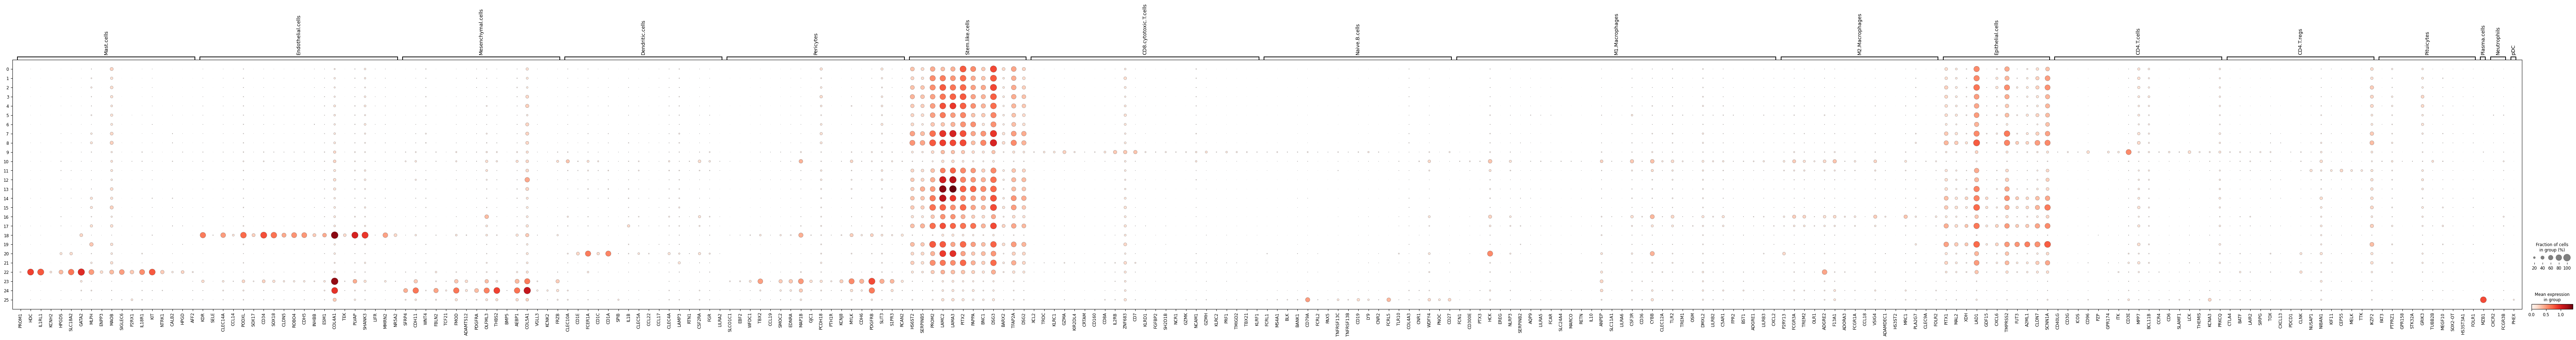

In [ ]:
sc.pl.dotplot(spatial_data,groupby= "leiden_scVI", var_names=dictionary,use_raw=False)

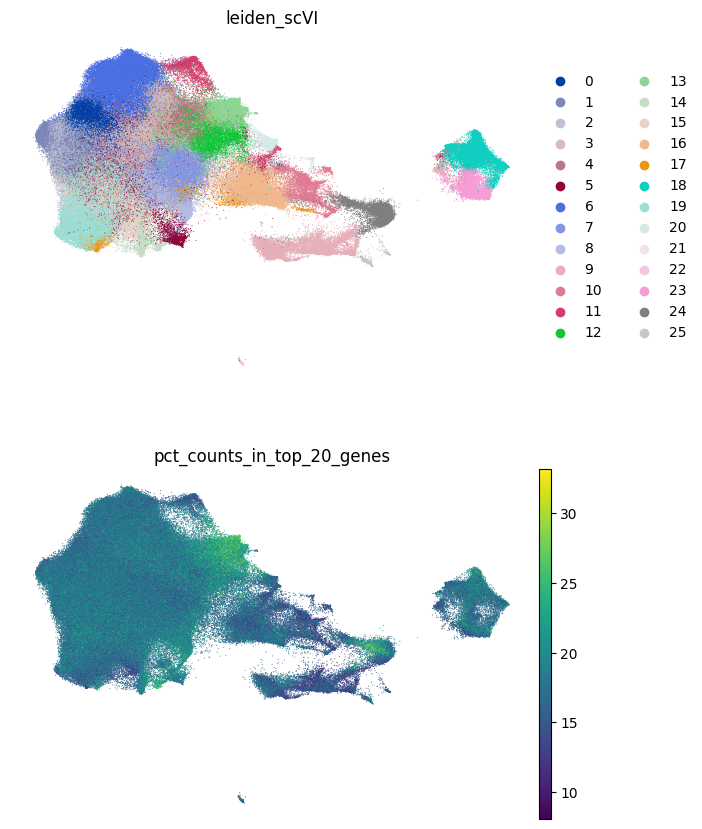

In [ ]:
sc.pl.umap(
    spatial_data,
    color=["leiden_scVI","pct_counts_in_top_20_genes"],
    frameon=False,
    sort_order=False,
    ncols=1,size=2
)

# Also calculating differential expression using scVI to further inform annotation

In [ ]:
de_df = vae.differential_expression(
    groupby="leiden_scVI"
)


DE...: 100%|██████████| 26/26 [11:04<00:00, 25.55s/it]


In [ ]:
groups=de_df["group1"].unique()
marker_dict = {}
for g in groups:
    subdf = de_df[de_df["group1"]==g]
    genes = subdf.head(10).index.values.tolist()
    genes = [g for g in genes if g in spatial_data.var_names]
    marker_dict[g] = genes
    print(subdf.head(20))


marker_dict

         proba_m1  proba_m2  bayes_factor    scale1    scale2  raw_mean1  \
TIAM1      0.9056    0.0944      2.261057  0.000418  0.000197   0.243208   
FAM131C    0.8916    0.1084      2.107189  0.000031  0.000011   0.021404   
FECH       0.8908    0.1092      2.098939  0.000215  0.000139   0.123313   
NTRK2      0.8898    0.1102      2.088700  0.000383  0.000112   0.210399   
MAP7       0.8786    0.1214      1.979239  0.001189  0.000767   0.506589   
DMKN       0.8546    0.1454      1.771145  0.000391  0.000269   0.202427   
UNG        0.8514    0.1486      1.745624  0.000288  0.000206   0.153916   
RRM1       0.8512    0.1488      1.744044  0.000992  0.000589   0.421111   
KCNK10     0.8486    0.1514      1.723663  0.000145  0.000057   0.083062   
F12        0.8486    0.1514      1.723663  0.000022  0.000011   0.014874   
NFE2L2     0.8470    0.1530      1.711263  0.002115  0.001401   0.693712   
SOD1       0.8462    0.1538      1.705103  0.001496  0.001030   0.548102   
TMTC4      0

{'0': ['TIAM1',
  'FAM131C',
  'FECH',
  'NTRK2',
  'MAP7',
  'DMKN',
  'UNG',
  'RRM1',
  'KCNK10',
  'F12'],
 '1': ['IGSF3',
  'MAN1B1',
  'NAV1',
  'BAIAP2',
  'EPHA1',
  'ENTPD2',
  'CELSR2',
  'C8G',
  'TMPRSS13',
  'ALOX15'],
 '2': ['IL1RN',
  'ALOX12',
  'GJB6',
  'TIAM1',
  'SLITRK4',
  'CTNND1',
  'TNFRSF11B',
  'EMP2',
  'MAPKAPK2',
  'LRATD2'],
 '3': ['CUL4A',
  'SLC7A11',
  'ABCB6',
  'PBX1',
  'GTF2I',
  'PLEKHA1',
  'TMEM164',
  'SNAP47',
  'PRLR',
  'PRPF8'],
 '4': ['RBBP8',
  'CSNK1G1',
  'TTC12',
  'CD274',
  'FAT1',
  'ABCB6',
  'SETD4',
  'NCOR2',
  'COL7A1',
  'C8B'],
 '5': ['PSMD4',
  'ALDOA',
  'GSK3A',
  'HSD17B10',
  'MIEN1',
  'PGK1',
  'SLC9A3R1',
  'ADIPOR1',
  'ELOC',
  'TSG101'],
 '6': ['TP73',
  'DLK2',
  'LTB4R',
  'LTB4R2',
  'MPPED1',
  'TP63',
  'NGFR',
  'DLL1',
  'ALDH3A2',
  'WNT3A'],
 '7': ['SESN3',
  'EFNB2',
  'MR1',
  'TMTC3',
  'FZD6',
  'FRAS1',
  'LGR4',
  'ERG28',
  'FBXW11',
  'MBL2'],
 '8': ['SLC25A10',
  'CHODL',
  'RHBDD2',
  'SEMA4B',
 

### Assigning clusters

In [ ]:
spatial_data.obs["broad_cluster"] = spatial_data.obs["leiden_scVI"].map(


    {

        "0": "Stem_like_cells", #
        "1": "Stem_like_cells", #
        "2":"Stem_like_cells",
        "3":"Stem_like_cells",
        "4":"Stem_like_cells",
        "5":"Stem_like_cells",
        "6":"Stem_like_cells",
        "7":"Epithelial_cells",
        "8":"Epithelial_cells", #
        "9":"T_cells", #
        "10":"Macrophages", #
        "11":"Stem_like_cells", #
        "12":"Stem_like_cells",
        "13":"Stem_like_cells",
        "14":"Epithelial_cells", #
        "15":"Epithelial_cells",#
        "16":"Macrophages",
        "17":"Epithelial_cells",#
        "18":"Endothelial_cells", #
        "19":"Epithelial_cells", #
        "20":"Dendritic_cells",
        "21":"Epithelial_cells",
        "22":"Mast_cells", #
        "23":"Pericytes", #
        "24":"Mesenchymal_cells", #
        "25":"B_cells" #


    }
)

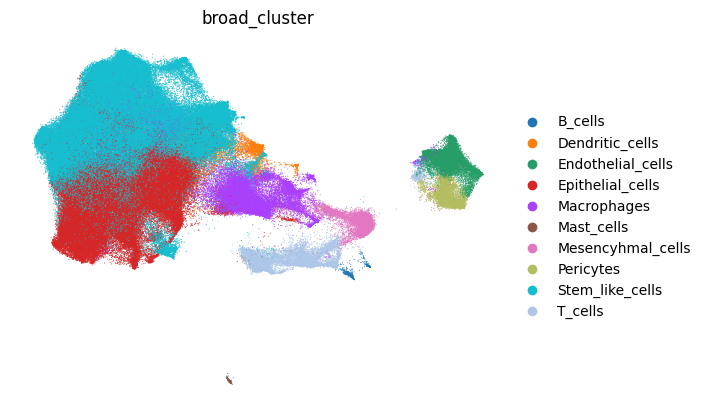

In [ ]:
sc.pl.umap(
    spatial_data,
    color=["broad_cluster"],
    frameon=False,
    sort_order=False,
    ncols=1,size=2
)

# Plotting genes in the final clusters

/home/darwin/miniconda3/envs/bencenv_wsl/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2058: FutureWarning: The method obs_keys is deprecated and will be removed in the future. Use obs instead of obs_keys. (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`)
  if group not in list(adata.obs_keys()) + [adata.obs.index.name]:


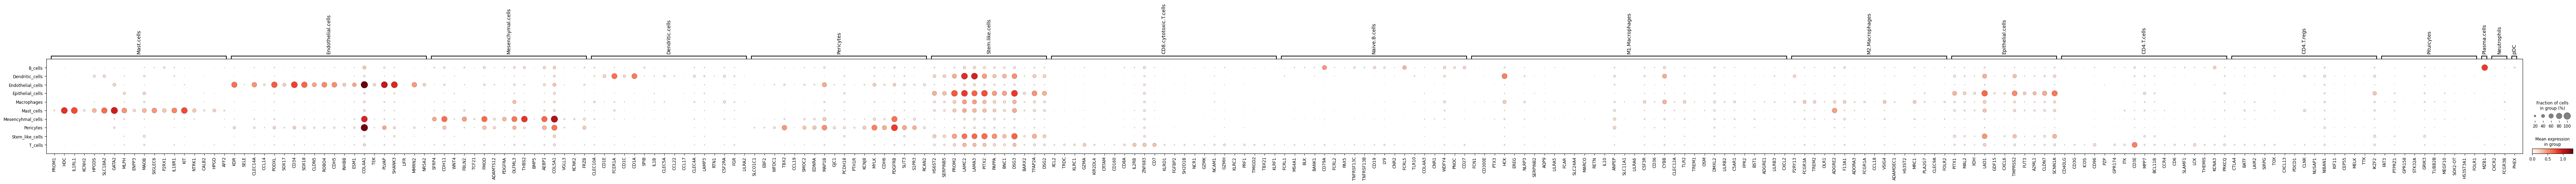

In [ ]:
sc.pl.dotplot(spatial_data,groupby= "broad_cluster", var_names=dictionary,use_raw=False)

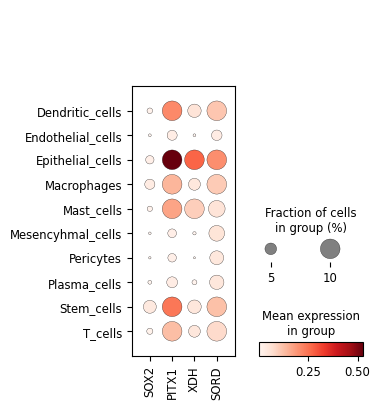

In [ ]:
sc.pl.dotplot(spatial_data,groupby= "broad_cluster", var_names=["SOX2","PITX1","XDH","SORD"],dot_max=0.1)

# saving object with resulting annotations

In [ ]:
spatial_data.write("/mnt/g/PCP_xenium/pcp_xenium_object_0618.h5ad",compression="gzip")

In [ ]:
pip freeze

absl-py==2.1.0
access==1.1.9
adjustText==1.3.0
affine==2.4.0
aiobotocore==2.19.0
aiohappyeyeballs==2.4.4
aiohttp==3.11.11
aioitertools==0.12.0
aiosignal==1.3.2
anndata==0.12.18
annotated-types==0.7.0
array-api-compat==1.15.0
asciitree==0.3.3
asttokens @ file:///opt/conda/conda-bld/asttokens_1646925590279/work
attrs==24.3.0
beautifulsoup4==4.13.3
biopython==1.87
bleach==6.4.0
botocore==1.36.3
Bottleneck @ file:///croot/bottleneck_1731058641041/work
certifi==2026.6.17
charset-normalizer==3.4.7
chex==0.1.88
choreographer==1.3.0
click==8.1.8
click-plugins==1.1.1
cligj==0.7.2
cloudpickle==3.1.1
colorcet==3.1.0
comm @ file:///croot/comm_1709322850197/work
contourpy==1.3.1
cycler==0.12.1
cykhash==2.0.1
dask==2024.11.2
dask-expr==1.1.19
dask-image==2024.5.3
datafusion==50.1.0
datashader==0.17.0
debugpy @ file:///croot/debugpy_1736267418885/work
decorator @ file:///opt/conda/conda-bld/decorator_1643638310831/work
decoupler==1.9.2
defusedxml==0.7.1
Deprecated==1.2.18
deprecation==2.1.0
dill==0.4